<h1>Required dataset and libraries importing</h1>
<p>CREDIT - AT&T Laboratories Cambridge for the dataset</p>

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score as accuracy
import matplotlib.pyplot as plt
from time import perf_counter
import joblib
from joblib import Parallel, delayed

C:\Users\gs070\AppData\Local\Temp\ipykernel_9368\2262964162.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
SEED=26018     # My roll no = M26CSE018
MAX_DEPTH=[2,4,8,16,None]
MIN_SAMLPLES_LEAF=[1,2,4]
B_VALUES = [1, 5, 10, 25, 50, 100, 200]

In [3]:
# Load data
data=fetch_olivetti_faces()
X=pd.DataFrame(data.data)
y=pd.DataFrame(data.target)

# Splitting the data as 6 images for training, 2 images for validation, and 2 images for testing for each subject
rng=np.random.default_rng(seed=SEED)
train_index, val_index, test_index=[], [], []
for i in range(40):
    index= np.arange(i*10,(i+1)*10)
    rng.shuffle(index)

    train_index.extend(index[:6])
    val_index.extend(index[6:8])
    test_index.extend(index[8:])

X_train,y_train =X.iloc[train_index], y.iloc[train_index]
X_val,y_val =X.iloc[val_index], y.iloc[val_index]
X_test,y_test =X.iloc[test_index], y.iloc[test_index]

In [4]:
# Saving training, validation and test sets to .npy files
np.savez('X_train.npy', X_train=X_train, y_train=y_train)
np.savez('X_val.npy', X_val=X_val, y_val=y_val)
np.savez('X_test.npy', X_test=X_test, y_test=y_test)

<h1>Ques-1</h1>
<h3>Decision tree baseline and bagging fr|om scratch</h3>
<p>(a) First establish a single tree baseline. Train DecisionTreeClassifier models with max depth∈ {2, 4, 8, 16, None}
and min samples leaf∈ {1, 2, 4}. Select one setting using validation accuracy only and freeze it. Report train,
validation and test accuracy, number of leaves, mean samples per leaf and the fraction of leaves containing only
one training example. Explain what changes as depth increases.</p>

In [5]:
# Part A
# Chechking the performance of DecisionTreeClassifier with different hyperparameters
A_results=[]
A_models={}
for depth in MAX_DEPTH:
    for min_samples in MIN_SAMLPLES_LEAF:
        model=DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_samples, random_state=SEED)
        model.fit(X_train,y_train)

        leaf_ids = model.apply(X_train)    # Get the leaf node ids of the training samples
        _, counts = np.unique(leaf_ids, return_counts=True)    # Return the unique leaf node ids and their samples counts

        result={"max_depth": "None" if depth is None else depth,
                "min_samples_leaf": min_samples,

                "train_accuracy": accuracy(y_train, model.predict(X_train)),
                "validation_accuracy": accuracy(y_val, model.predict(X_val)),
                "test_accuracy": accuracy(y_test, model.predict(X_test)),

                "leaves": int(len(counts)),
                "mean_samples_per_leaf": float(np.mean(counts)),
                "fraction_single_sample_leaves": float(np.mean(counts == 1)),

                }
        A_results.append(result)
        A_models[(depth, min_samples)] = model

selected_para = max(A_results, key= lambda x: x["validation_accuracy"])
selected_depth = None if selected_para["max_depth"] == "None" else int(selected_para["max_depth"])
selected_leaf = int(selected_para["min_samples_leaf"])
selected_model = A_models[(selected_depth, selected_leaf)]
print(selected_depth,selected_leaf)

None 4


In [6]:
A_results

[{'max_depth': 2,
  'min_samples_leaf': 1,
  'train_accuracy': 0.075,
  'validation_accuracy': 0.075,
  'test_accuracy': 0.05,
  'leaves': 3,
  'mean_samples_per_leaf': 80.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 2,
  'min_samples_leaf': 2,
  'train_accuracy': 0.075,
  'validation_accuracy': 0.075,
  'test_accuracy': 0.05,
  'leaves': 3,
  'mean_samples_per_leaf': 80.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 2,
  'min_samples_leaf': 4,
  'train_accuracy': 0.075,
  'validation_accuracy': 0.075,
  'test_accuracy': 0.05,
  'leaves': 3,
  'mean_samples_per_leaf': 80.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 4,
  'min_samples_leaf': 1,
  'train_accuracy': 0.125,
  'validation_accuracy': 0.1,
  'test_accuracy': 0.075,
  'leaves': 5,
  'mean_samples_per_leaf': 48.0,
  'fraction_single_sample_leaves': 0.0},
 {'max_depth': 4,
  'min_samples_leaf': 2,
  'train_accuracy': 0.125,
  'validation_accuracy': 0.1,
  'test_accuracy': 0.075,
  'leaves':

In [7]:
# Saving the selected model to baseline_model.joblib
joblib.dump(selected_model, 'baseline_model.joblib')

['baseline_model.joblib']

<p style = "margin-top: 50px;">(b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting
from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the
average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical
expectation.

(c) For every B, compute out of bag accuracy, average pairwise disagreement between trees, and mean vote margin,
where vote margin is the winning vote fraction minus the runner up vote fraction. Plot all three against B. Select
one final ensemble size using the validation set and explain whether out of bag accuracy, disagreement and vote
margin tell the same story.</p>

In [8]:
def vote_majority(X, classes , models):
    """Return majority-vote predictions, vote counts and winning vote fraction"""
    predictions = np.array([model.predict(X) for model in models])

    # Get the majority vote for each sample (by slicing predictions column-wise) and select the class with the highest count
    majority_vote = np.apply_along_axis(lambda x: np.bincount(x, minlength=len(classes)).argmax(), axis=0, arr=predictions)
    return majority_vote, predictions

In [9]:
def oob_accuracy(current_models, current_memberships, X_train, y_train):
    classes = np.unique(y_train)
    oob_votes = np.zeros((X_train.shape[0], len(classes)))   # store aggregated votes/predictions for each training sample
    
    class_to_col = {c: j for j, c in enumerate(classes)}     # map class labels to column indices in oob_votes
    
    for model, inbag in zip(current_models, current_memberships):
        oob_idx = np.flatnonzero(~inbag)
        if len(oob_idx) == 0:
            continue
            
        preds = model.predict(X_train.iloc[oob_idx, :])
        for idx, pred in zip(oob_idx, preds):
                    oob_votes[idx, class_to_col[pred]] += 1
    has_oob = oob_votes.sum(axis=1) > 0
    if not np.any(has_oob):
        return float("nan"), int(0)
    preds = classes[np.argmax(oob_votes[has_oob], axis=1)]
    return accuracy(y_train[has_oob], preds)

In [10]:
def pairwise_disagreement(all_predictions):
    """Mean fraction of examples on which each pair of trees disagrees."""
    n_models = all_predictions.shape[0]

    if n_models < 2:
        return 0.0

    values = []
    for i in range(n_models):
        for j in range(i + 1, n_models):
            disagreement = np.mean(all_predictions[i] != all_predictions[j])
            values.append(disagreement)

    return float(np.mean(values))

In [11]:
def mean_vote_margin(current_models, X):
    predictions = np.array([model.predict(X) for model in current_models]).T
    B = predictions.shape[1]

    margins = []

    for row in predictions:
        votes = np.bincount(row, minlength=40) 
        sorted_votes = np.sort(votes)[::-1]
        largest = sorted_votes[0]
        second_largest = sorted_votes[1] if len(sorted_votes) > 1 else 0

        winning_fraction = largest / B
        runner_up_fraction = second_largest / B
        margin = winning_fraction - runner_up_fraction
        margins.append(margin)

    return np.mean(margins)

In [12]:
# Part B and C
# Bagging with different number of base learners

rng = np.random.default_rng(seed=SEED)
B_models=[]
n = len(y_train)
classes = np.unique(y_train)
memberships = []

B_C_results = []

for B in B_VALUES:
    while len(B_models) < B:
        indices=rng.integers(low=0, high=n, size=n)
        inbag = np.zeros(n, dtype=bool)
        inbag[np.unique(indices)] = True

        model = DecisionTreeClassifier(max_depth=selected_depth, min_samples_leaf=selected_leaf, random_state=SEED)
        model.fit(X_train.iloc[indices], y_train.iloc[indices])
        B_models.append(model)
        memberships.append(inbag)

    current_models = B_models[:B]
    current_memberships = memberships[:B]

    
    train_pred, train_predictions = vote_majority(X_train, classes, current_models)
    val_pred, val_predictions = vote_majority(X_val, classes, current_models)
    test_pred, test_predictions = vote_majority(X_test, classes, current_models)

     # Average unique original training examples represented in each bootstrap.
    distinct_mean = float(np.mean([m.sum() for m in current_memberships]))

    # OOB accuracy
    oob_acc=oob_accuracy(current_models, current_memberships, X_train, y_train)


    result = {
        "B": B,
        "train_accuracy": accuracy(y_train, train_pred),
        "validation_accuracy": accuracy(y_val, val_pred),
        "test_accuracy": accuracy(y_test, test_pred),
        "avg_distinct_training_examples": distinct_mean,
        "theoretical_distinct_expectation": n * (1 - (1 - 1 / n) ** n),
        "oob_accuracy": oob_acc,
        "avg_pairwise_disagreement": pairwise_disagreement(train_predictions),
        "mean_vote_margin": mean_vote_margin(current_models, X_train)
    }
    B_C_results.append(result)

results_df = pd.DataFrame(B_C_results)

In [13]:
best_val = results_df["validation_accuracy"].max()
best_val_model = results_df[results_df["validation_accuracy"] == best_val]
best_val_model = best_val_model.head(1)    # Selects smallest B if validation accuracy is same but in our seed there is no clash over val_acc
selected_bagged_models = B_models[:int(best_val_model["B"])]
print(len(selected_bagged_models))

100


C:\Users\gs070\AppData\Local\Temp\ipykernel_9368\675125559.py:4: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  selected_bagged_models = B_models[:int(best_val_model["B"])]


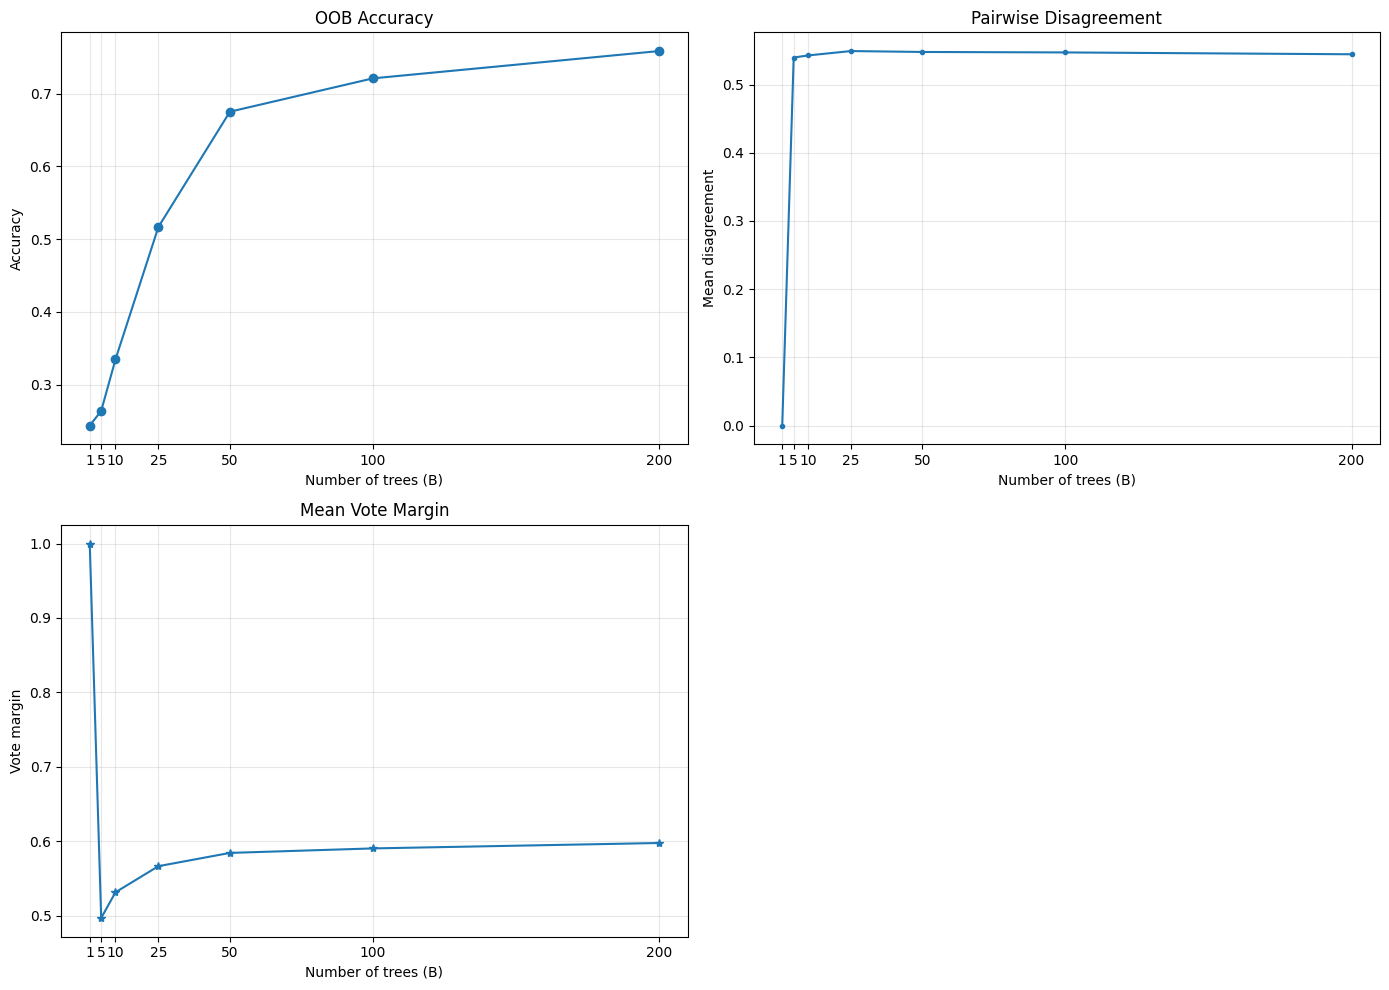

In [14]:
# Plot OOB accuracy, pairwise disagreement and mean vote margin
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

axes[0].plot(results_df["B"], results_df["oob_accuracy"], marker="o")
axes[0].set_title("OOB Accuracy")
axes[0].set_xlabel("Number of trees (B)")
axes[0].set_ylabel("Accuracy")

axes[1].plot(results_df["B"], results_df["avg_pairwise_disagreement"], marker=".")
axes[1].set_title("Pairwise Disagreement")
axes[1].set_xlabel("Number of trees (B)")
axes[1].set_ylabel("Mean disagreement")

axes[2].plot(results_df["B"], results_df["mean_vote_margin"], marker="*")
axes[2].set_title("Mean Vote Margin")
axes[2].set_xlabel("Number of trees (B)")
axes[2].set_ylabel("Vote margin")

for ax in axes:
    ax.set_xticks(B_VALUES)
    ax.grid(True, alpha=0.3)

axes[3].axis("off")
plt.tight_layout()
plt.savefig("q1c_metrics.png", dpi=200)
plt.show()

In [15]:
# Saving model
final_B = 100

# using first 100 trees from existing ensemble trees
final_bagged_trees = B_models[:final_B]

joblib.dump(final_bagged_trees, 'bagging_model.joblib')

['bagging_model.joblib']

<p style = "margin-top: 50px;">(d) Compare the frozen single tree and the final bagged model on both the clean and masked test sets. Report
accuracy and prediction confidence for both. Find two faces where bagging corrects the tree and two where both
are wrong. Show the tree prediction and bagging vote counts, and use these cases to explain what type of error
bagging can reduce and what type it cannot.</p>

In [16]:
def bagging_confidence(models, X):
    votes = np.array([model.predict(X) for model in models]).T
    confidence = []

    for row in votes:
        counts = np.bincount(row, minlength=40)
        confidence.append(counts.max() / len(models))

    return np.array(confidence)

In [17]:
# Part D
# Setting rows 24-39 and columns 24-39 to zero, then flatten again
X_test_masked = np.asarray(X_test).reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0.0
X_test_masked=X_test_masked.reshape(-1 , 4096)

D_results=[]
for dataset, X_eval in [("clean", X_test), ("masked", X_test_masked)]:
    single_pred = selected_model.predict(X_eval)
    single_accuracy = accuracy(y_test, single_pred)
    single_confidence = selected_model.predict_proba(X_eval).max(axis=1).mean()

    bagged_pred, _ = vote_majority(X_eval, np.unique(y_train), selected_bagged_models)
    bagged_accuracy = accuracy(y_test, bagged_pred)
    bagged_confidence = bagging_confidence(selected_bagged_models, X_eval).mean()

    result = {
        "dataset": dataset,
        "single_tree_accuracy": single_accuracy,
        "single_tree_confidence": single_confidence,
        "bagging_accuracy": bagged_accuracy,
        "bagged_trees_confidence": bagged_confidence,
    }
    D_results.append(result)

D_comparison = pd.DataFrame(D_results)
D_comparison

,dataset,single_tree_accuracy,single_tree_confidence,bagging_accuracy,bagged_trees_confidence
0,clean,0.5625,0.953571,0.8625,0.380750
1,masked,0.0750,1.000000,0.6750,0.256125


In [18]:
# Let's consider clean test_set for furthur evaluation
y_test_array = y_test.to_numpy().ravel()
single_pred = selected_model.predict(X_test)
bagged_pred, predictions = vote_majority(X_test, np.unique(y_train), selected_bagged_models)

# Case 1: Single tree is wrong, but bagging is correct
mask_1 = (single_pred != y_test_array) & (bagged_pred == y_test_array)
correct_indices = np.where(mask_1)[0]
two_correct_indices = correct_indices[:2]

# Case 2: Both single tree and bagging fails
mask_2 = (single_pred != y_test_array) & (bagged_pred != y_test_array)
wrong_indices = np.where(mask_2)[0]
two_wrong_indices = wrong_indices[:2]

# Bagging vote count
combined_indices = np.concatenate((two_correct_indices,two_wrong_indices))
bagged_count = []


# print("Two indices where single tree is wrong but bagged trees are correct :-")
# print(f"Indices = {two_correct_indices}    True Label = {y_test_array[two_correct_indices]}    Single tree predict = {single_pred[two_correct_indices]}    Bagging predict = {bagged_pred[two_correct_indices]}")
# print()
# print("Two indices where both single tree and bagged trees are wrong :-")
# print(f"Indices = {two_wrong_indices}    True Label = {y_test_array[two_wrong_indices]}    Single tree predict = {single_pred[two_wrong_indices]}    Bagging predict = {bagged_pred[two_wrong_indices]}")

for index in combined_indices:
    votes = predictions[: , index]
    counts = np.bincount(votes, minlength=40)
    print("Image index: ", index)
    print("True Label: ", y_test_array[index])
    print("Single tree predict: ", single_pred[index])
    print("Bagging predict: ", bagged_pred[index])
    print("Bagging majority count: ", counts.max())
    print("Non-zero class votes:", {i: int(c) for i,c in enumerate(counts) if c>0})
    print()     

Image index:  2
True Label:  1
Single tree predict:  31
Bagging predict:  1
Bagging majority count:  58
Non-zero class votes: {0: 1, 1: 58, 2: 2, 3: 2, 8: 1, 9: 1, 10: 1, 11: 3, 12: 5, 13: 2, 14: 1, 15: 3, 16: 1, 18: 1, 20: 2, 22: 1, 23: 1, 26: 1, 27: 1, 30: 5, 31: 4, 33: 2, 37: 1}

Image index:  5
True Label:  2
Single tree predict:  3
Bagging predict:  2
Bagging majority count:  26
Non-zero class votes: {0: 4, 2: 26, 3: 8, 4: 1, 6: 1, 9: 1, 12: 3, 13: 1, 15: 1, 16: 3, 21: 1, 22: 2, 25: 9, 27: 11, 31: 1, 34: 3, 36: 9, 37: 12, 39: 3}

Image index:  9
True Label:  4
Single tree predict:  39
Bagging predict:  2
Bagging majority count:  20
Non-zero class votes: {0: 1, 1: 1, 2: 20, 3: 4, 4: 8, 5: 1, 8: 3, 9: 4, 10: 1, 11: 1, 12: 8, 13: 1, 14: 9, 15: 4, 16: 3, 17: 8, 18: 2, 19: 1, 20: 3, 21: 1, 22: 1, 23: 2, 24: 1, 27: 1, 28: 1, 33: 1, 34: 3, 35: 1, 37: 1, 38: 1, 39: 3}

Image index:  20
True Label:  10
Single tree predict:  31
Bagging predict:  31
Bagging majority count:  31
Non-zero class

<h1 style = "margin-top: 50px;">Ques-2</h1>
<h3>Implement SAMME AdaBoost yourself. For K classes, using given formulas:</h3>
<h4>Handle explicitly any weak learner that is not better than random multiclass prediction. For confidence use the normalised weighted vote qk(x) = Sk(x)/ tαt.</h4>
<p>(a) Before using the face data, create a three class example with at most 10 samples. Log one complete SAMME round: initial sample weights, weak learner predictions, weighted error, αt, and updated normalised weights. Your implementation on the face data must use the same update rule.</p>

In [19]:
# Part A
X_sample = np.array([[0], [1], [2], [3], [4], [5]])
y_sample = np.array(["A", "A", "B", "B", "C", "C"])

sample_weights = np.ones(len(y_sample)) / len(y_sample)
sample_tree = DecisionTreeClassifier(max_depth=1, random_state=SEED)
sample_tree.fit(X_sample, y_sample, sample_weight=sample_weights)

sample_predictions = sample_tree.predict(X_sample)
sample_incorrect = sample_predictions != y_sample
sample_error = float(sample_weights[sample_incorrect].sum())

K_sample = len(np.unique(y_sample))
random_error_limit = 1 - 1 / K_sample

print("One SAMME round on a six-sample, three-class example \n")
print("Initial weights:", sample_weights)
print("True labels:", y_sample)
print("Weak learner predictions:", sample_predictions)
print("Weighted error:", sample_error)

if sample_error < random_error_limit:
    sample_alpha = ( np.log((1 - sample_error) / sample_error) + np.log(K_sample - 1))
    updated_weights = sample_weights.copy()
    updated_weights[sample_incorrect] *= np.exp(sample_alpha)
    updated_weights /= updated_weights.sum()

    print("Alpha:", sample_alpha)
    print("Updated normalised weights:", updated_weights)
    print("Updated weight sum:", updated_weights.sum())
else:
    print(
        "This weak learner is not better than random multiclass prediction; "
        "SAMME must reject it and not update the weights."
    )

One SAMME round on a six-sample, three-class example 

Initial weights: [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
True labels: ['A' 'A' 'B' 'B' 'C' 'C']
Weak learner predictions: ['A' 'A' 'B' 'B' 'B' 'B']
Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908
Updated normalised weights: [0.08333333 0.08333333 0.08333333 0.08333333 0.33333333 0.33333333]
Updated weight sum: 1.0


<p style = "margin-top: 50px;">(b) On Olivetti Faces, use weak learner depths 1, 2, 3, 4 and 10, 25, 50, 100 rounds. Select depth and rounds using clean validation accuracy only. For the selected model, plot weighted training error, learner weight, maximum sample weight and the total weight carried by the 10 heaviest training images over rounds.</p>

In [20]:

def train_samme(X, y, max_depth, n_rounds, random_state=SEED):
    """Train a multiclass SAMME ensemble using sample weights."""
    X = np.asarray(X)
    y = np.asarray(y).ravel()

    n_samples = len(y)
    classes = np.unique(y)
    K = len(classes)

    if n_samples == 0 or len(X) != n_samples:
        raise ValueError("X and y must contain the same non-zero number of samples.")
    if K < 2:
        raise ValueError("SAMME requires at least two classes.")
    if n_rounds < 1:
        raise ValueError("n_rounds must be at least 1.")

    weights = np.ones(n_samples, dtype=float) / n_samples
    rng = np.random.default_rng(random_state)

    trees = []
    alphas = []
    weighted_errors = []
    max_sample_weights = []
    top10_weight_sums = []

    random_error_limit = 1 - 1 / K

    for t in range(n_rounds):
        tree = DecisionTreeClassifier(max_depth=max_depth,random_state=SEED)
        tree.fit(X, y, sample_weight=weights)
        predictions = tree.predict(X)

        incorrect = predictions != y
        weighted_error = float(weights[incorrect].sum())

        # A learner at or above the random-guessing threshold is rejected.
        if weighted_error >= random_error_limit:
            print(
                f"Stopping at round {t + 1}: weighted error "
                f"{weighted_error:.6f} is not below "
                f"{random_error_limit:.6f}."
            )
            break

        # Store diagnostics for the current round before updating weights.
        weighted_errors.append(weighted_error)
        max_sample_weights.append(float(weights.max()))
        top10_weight_sums.append(float(np.sort(weights)[-min(10, n_samples):].sum()))
        trees.append(tree)

        # Avoid an infinite alpha for a perfect learner.
        if weighted_error <= 1e-12:
            alpha = np.log((1 - 1e-12) / 1e-12) + np.log(K - 1)
            alphas.append(float(alpha))
            print(f"Perfect learner reached at round {t + 1}; stopping.")
            break

        alpha = (np.log((1 - weighted_error) / weighted_error) + np.log(K - 1))
        alphas.append(float(alpha))

        # SAMME update: increase only the weights of misclassified samples.
        weights[incorrect] *= np.exp(alpha)
        weights /= weights.sum()

    return {
        "trees": trees,
        "alphas": alphas,
        "weighted_errors": weighted_errors,
        "max_sample_weights": max_sample_weights,
        "top10_weight_sums": top10_weight_sums,
        "final_sample_weights": weights.copy(),
    }

In [21]:
def samme_scores(model, X):
    """Return the SAMME class scores for each sample."""

    X = np.asarray(X)
    trees = model["trees"]
    alphas = model["alphas"]

    if len(trees) == 0:
        raise ValueError("SAMME trained no accepted weak learners.")

    classes = trees[0].classes_
    scores = np.zeros((len(X), len(classes)), dtype=float)    # stores score of (each image , class) 

    for tree, alpha in zip(trees, alphas):
        predictions = tree.predict(X)

        for i, label in enumerate(predictions):
            scores[i, label] += alpha

    return scores

In [22]:
def predict_samme(model, X):
    scores = samme_scores(model, X)
    classes = model["trees"][0].classes_
    return classes[np.argmax(scores, axis=1)]

In [23]:
def predict_samme_confidence(model, X):
    """Normalised winning weighted vote; this is not a calibrated probability."""
    scores = samme_scores(model, X)
    total_alpha = np.sum(model["alphas"])
    if total_alpha <= 0:
        raise ValueError("Total SAMME learner weight must be positive.")
    return scores.max(axis=1) / total_alpha

In [24]:
# Select depth and rounds using validation accuracy only.
BOOST_DEPTHS = [1, 2, 3, 4]
BOOST_ROUNDS = [10, 25, 50, 100]

boosting_results = []
boosting_candidates = {}

for depth in BOOST_DEPTHS:
    for rounds in BOOST_ROUNDS:
        model = train_samme(X_train, y_train, max_depth=depth, n_rounds=rounds, random_state=SEED)
        val_pred = predict_samme(model, X_val)
        val_acc = float(np.mean(val_pred == y_val.to_numpy().ravel()))

        boosting_candidates[(depth, rounds)] = model
        boosting_results.append({
            "max_depth": depth,
            "rounds_requested": rounds,
            "rounds_trained": len(model["trees"]),
            "validation_accuracy": val_acc,
        })

boosting_results_df = pd.DataFrame(boosting_results)
boosting_results_df

,max_depth,rounds_requested,rounds_trained,validation_accuracy
0,1,10,10,0.0500
1,1,25,25,0.0500
2,1,50,50,0.1375
3,1,100,100,0.1250
4,2,10,10,0.0625
5,2,25,25,0.1125
6,2,50,50,0.1625
7,2,100,100,0.2375
8,3,10,10,0.1625
9,3,25,25,0.2750


In [25]:
# Validation accuracy is the only selection metric; ties keep the first grid setting.
best_row = max(
    boosting_results,
    key=lambda row: row["validation_accuracy"]
)
MAX_DEPTH = int(best_row["max_depth"])
N_ROUNDS = int(best_row["rounds_requested"])
boostingModel = boosting_candidates[(MAX_DEPTH, N_ROUNDS)]

print(
    f"Selected SAMME model: max_depth={MAX_DEPTH}, "
    f"rounds requested={N_ROUNDS}, "
    f"rounds trained={len(boostingModel['trees'])}, "
    f"validation accuracy={best_row['validation_accuracy']:.4f}"
)

Selected SAMME model: max_depth=4, rounds requested=100, rounds trained=100, validation accuracy=0.5750


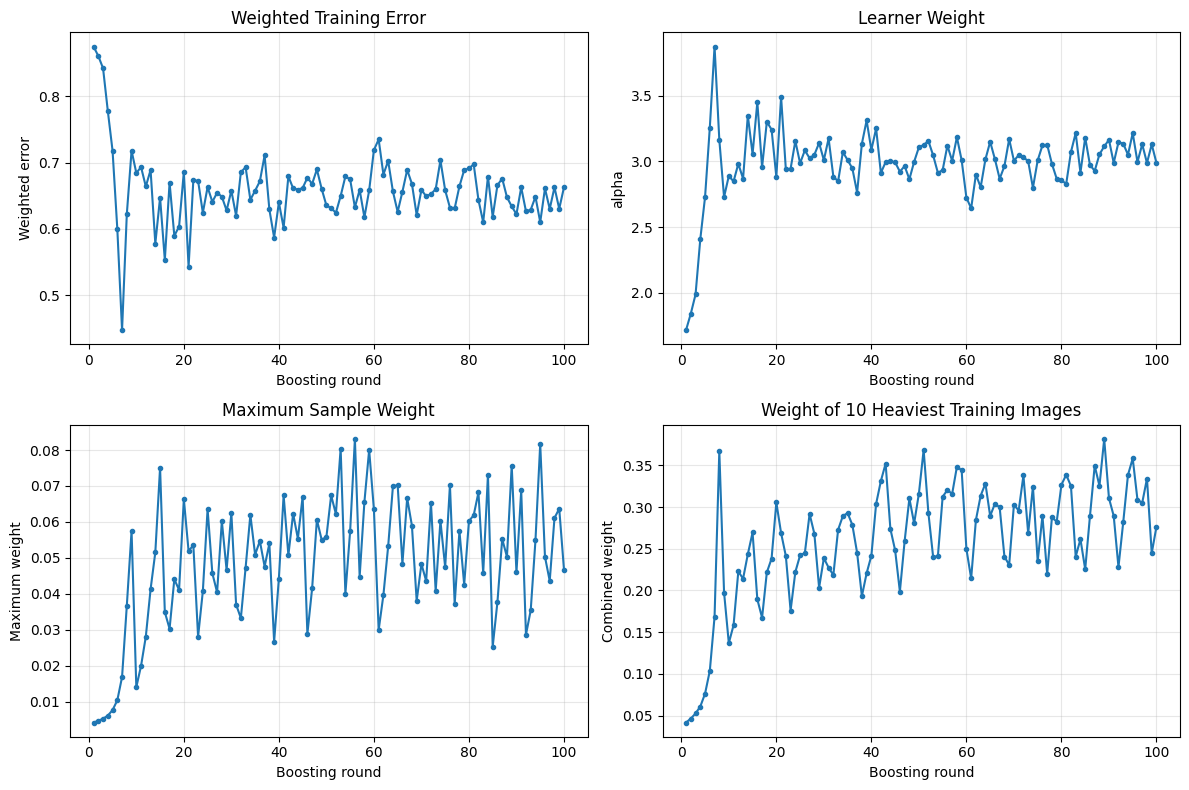

In [26]:
# Plot all four required diagnostics for the selected boosting model.
round_numbers = np.arange(1, len(boostingModel["trees"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plots = [
    (boostingModel["weighted_errors"], "Weighted Training Error", "Weighted error"),
    (boostingModel["alphas"], "Learner Weight", r"alpha"),
    (boostingModel["max_sample_weights"], "Maximum Sample Weight", "Maximum weight"),
    (boostingModel["top10_weight_sums"], "Weight of 10 Heaviest Training Images", "Combined weight"),
]

for ax, (values, title, ylabel) in zip(axes.flat, plots):
    ax.plot(np.arange(1, len(values) + 1), values, marker=".")
    ax.set_title(title)
    ax.set_xlabel("Boosting round")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<p style = "margin-top: 50px;">(c) Compare boosting and bagging using 25, 50 and 100 learners. Report train, validation and clean test accuracy and training time. Also inspect one training face that receives a very large boosting weight and use its prediction history to explain why boosting repeatedly returns attention to that sample.</p>

In [27]:
# Part C
comparison_results = []
bagged_models_by_B = {}
boosted_models_by_B = {}
classes = np.unique(y_train)

for B in [25, 50, 100]:
    # Bagging: train a fresh ensemble and measure actual training time.
    start = perf_counter()
    bagged_trees = []
    rng_bagging = np.random.default_rng(SEED)
    
    X_train_np = np.asarray(X_train)
    y_train_np = np.asarray(y_train).ravel()
    n_train = len(X_train_np)
    
    for b in range(B):
        bootstrap_indices = rng_bagging.integers(0, n_train, size=n_train)
        tree = DecisionTreeClassifier(max_depth=selected_depth, min_samples_leaf=selected_leaf, random_state=SEED)
        tree.fit(X_train_np[bootstrap_indices], y_train_np[bootstrap_indices])
        bagged_trees.append(tree)
    
    bagging_time = perf_counter() - start
    bagged_models_by_B[B] = bagged_trees

    # Boosting uses the selected depth from Q2(b).
    start = perf_counter()
    boosted_model = train_samme(X_train, y_train, max_depth=MAX_DEPTH, n_rounds=B, random_state=SEED)
    boosting_time = perf_counter() - start
    boosted_models_by_B[B] = boosted_model

    for model_name, model, train_time in [("Bagging", bagged_trees, bagging_time), ("SAMME", boosted_model, boosting_time)]:
        if model_name == "Bagging":
            train_pred, _ = vote_majority(X_train, classes, model)
            val_pred, _ = vote_majority(X_val, classes, model)
            test_pred, _ = vote_majority(X_test, classes, model)
            n_learners = len(model)
        else:
            train_pred = predict_samme(model, X_train)
            val_pred = predict_samme(model, X_val)
            test_pred = predict_samme(model, X_test)
            n_learners = len(model["trees"])

        comparison_results.append({
            "model": model_name,
            "learners_requested": B,
            "learners_trained": n_learners,
            "train_accuracy": float(np.mean(train_pred == y_train.to_numpy().ravel())),
            "validation_accuracy": float(np.mean(val_pred == y_val.to_numpy().ravel())),
            "clean_test_accuracy": float(np.mean(test_pred == y_test.to_numpy().ravel())),
            "training_time_seconds": train_time,
        })

comparison_df = pd.DataFrame(comparison_results)
comparison_df

,model,learners_requested,learners_trained,train_accuracy,validation_accuracy,clean_test_accuracy,training_time_seconds
0,Bagging,25,25,1.000000,0.8125,0.8000,69.982900
1,SAMME,25,25,0.541667,0.2875,0.1750,21.336709
2,Bagging,50,50,1.000000,0.8250,0.8375,136.132179
3,SAMME,50,50,0.937500,0.4125,0.3125,20.407760
4,Bagging,100,100,1.000000,0.8625,0.8625,125.676046
5,SAMME,100,100,1.000000,0.5750,0.5000,39.042319


Training image index: 238
True identity: 39
Final sample weight: 0.06876535922769525
Initial sample weight: 0.004166666666666667
Rounds misclassified: 88 of 100
Prediction history: [ 0  1  2  3  4  9 12 39  1  2  3 11 39  9 12 17  2  3 25 39 39 12 14  2
  8  3 30  4 34 14 20  2  8  3 39  5 22 14 20 26  3 39  4 12 14 20  2  8
 23 39  4 12 14 20 22 23 39 25  4 14 20 37  2 12 39 29 22 14 20 37 26  8
  3 17 39 14 20  0 18 23  3 39  4 14 20  2 12  3 39  5  4 20 34 12 23  3
 22  4 16 20]


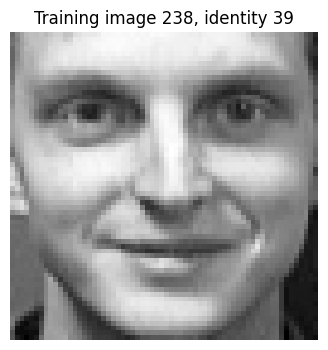

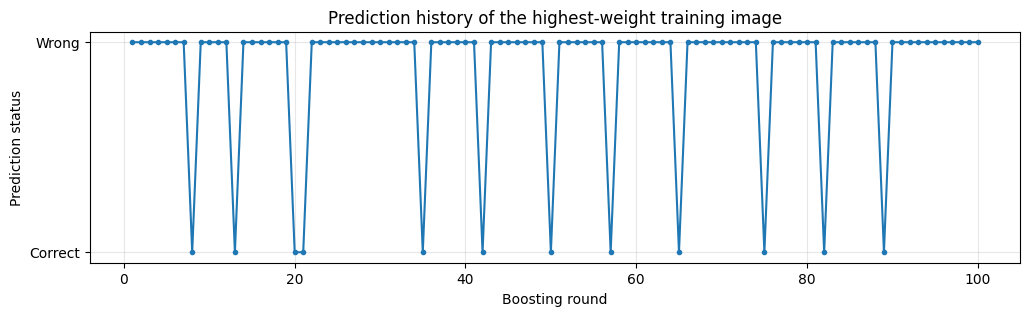

In [28]:
# Inspect the training image with the largest final SAMME weight.
final_weights = boostingModel["final_sample_weights"]
hard_index = int(np.argmax(final_weights))

hard_history = np.array([
    tree.predict(X_train[hard_index:hard_index + 1])[0]
    for tree in boostingModel["trees"]
])

hard_wrong = hard_history != np.asarray(y_train).ravel()[hard_index]

print("Training image index:", hard_index)
print("True identity:", np.asarray(y_train).ravel()[hard_index])
print("Final sample weight:", final_weights[hard_index])
print("Initial sample weight:", 1 / len(y_train))
print("Rounds misclassified:", int(hard_wrong.sum()), "of", len(hard_wrong))
print("Prediction history:", hard_history)

plt.figure(figsize=(4, 4))
plt.imshow(X_train.iloc[hard_index].to_numpy().reshape(64, 64), cmap="gray")
plt.title(
    f"Training image {hard_index}, identity "
    f"{np.asarray(y_train).ravel()[hard_index]}"
)
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 3))
plt.plot(
    np.arange(1, len(hard_history) + 1),
    hard_wrong.astype(int),
    marker="."
)
plt.yticks([0, 1], ["Correct", "Wrong"])
plt.xlabel("Boosting round")
plt.ylabel("Prediction status")
plt.title("Prediction history of the highest-weight training image")
plt.grid(True, alpha=0.3)
plt.show()

In [40]:
# Saving model
joblib.dump(boostingModel, 'boostingModel.joblib')

# Save configuration metadata for reproducibility
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 4,
    "bagging_max_depth": None,
    "bagging_min_samples_leaf": 4,
    "bagging_n_estimators": 100,
    "boosting_max_depth": 4,
    "boosting_n_rounds": 100,
    "random_seed": 26018
}

joblib.dump(config, "model_config.joblib")

['model_config.joblib']

<p style = "margin-top: 50px;">(d) Freeze the selected boosting model. Evaluate the single tree baseline, final bagged model and boosting model on the clean and masked test sets. Report accuracy and mean winning vote or probability for each. Find one face for which bagging and boosting respond differently to the missing region and explain the difference using tree disagreement and boosting sample weighting.</p>

In [30]:
# Part D
# Build the masked test set if it has not already been created in Q1.
X_masked_test = np.asarray(X_test).reshape(-1, 64, 64).copy()
X_masked_test[:, 24:40, 24:40] = 0
X_masked_test = X_masked_test.reshape(-1, 4096)

comparison_rows = []
predictions_by_set = {}

for dataset, X_eval in [("clean", X_test), ("masked", X_masked_test)]:
    # Single baseline model
    single_pred = selected_model.predict(X_eval)
    single_accuracy = accuracy(y_test, single_pred)
    single_conf = selected_model.predict_proba(X_eval).max(axis=1)

    # Frozen final bagged model from Q1
    bagged_pred, _ = vote_majority(X_eval, np.unique(y_train), selected_bagged_models)
    bagged_accuracy = accuracy(y_test, bagged_pred)
    bagged_conf = bagging_confidence(selected_bagged_models, X_eval)

    # Frozen selected SAMME model from Q2(b)
    boost_pred = predict_samme(boostingModel, X_eval)
    boost_accuracy = accuracy(y_test, boost_pred)
    boost_conf = predict_samme_confidence(boostingModel, X_eval)

    predictions_by_set[dataset] = {
        "tree_pred": single_pred,
        "bag_pred": bagged_pred,
        "boost_pred": boost_pred,
        "tree_conf": single_conf,
        "bag_conf": bagged_conf,
        "boost_conf": boost_conf,
    }

    comparison_rows.extend([
        {
            "dataset": dataset,
            "model": "Single tree",
            "accuracy": single_accuracy,
            "mean_winning_vote_or_probability": float(np.mean(single_conf)),
        },
        {
            "dataset": dataset,
            "model": "Bagging",
            "accuracy": bagged_accuracy,
            "mean_winning_vote_or_probability": float(np.mean(bagged_conf)),
        },
        {
            "dataset": dataset,
            "model": "SAMME boost",
            "accuracy": boost_accuracy,
            "mean_winning_vote_or_probability": float(np.mean(boost_conf)),
        },
    ])

q2d_results_df = pd.DataFrame(comparison_rows)
q2d_results_df

,dataset,model,accuracy,mean_winning_vote_or_probability
0,clean,Single tree,0.5625,0.953571
1,clean,Bagging,0.8625,0.380750
2,clean,SAMME boost,0.5000,0.114924
3,masked,Single tree,0.0750,1.000000
4,masked,Bagging,0.6750,0.256125
5,masked,SAMME boost,0.4500,0.110392



Example with different bagging/boosting response to masking
Test index: 5
True identity: 2
Bagging clean prediction: 2
Bagging masked prediction: 2
Bagging clean and masked winning vote fraction: 0.26     0.14
Boosting clean prediction: 3
Boosting masked prediction: 2
Boosting clean/masked normalised weighted vote: 0.1098498859084951 0.10560022073674315
Bagging votes (clean): {0: 4, 2: 26, 3: 8, 4: 1, 6: 1, 9: 1, 12: 3, 13: 1, 15: 1, 16: 3, 21: 1, 22: 2, 25: 9, 27: 11, 31: 1, 34: 3, 36: 9, 37: 12, 39: 3}
Bagging votes (masked): {0: 2, 2: 14, 3: 4, 9: 1, 11: 1, 12: 6, 13: 12, 16: 1, 19: 1, 20: 2, 23: 1, 25: 7, 26: 3, 27: 7, 30: 5, 31: 1, 33: 13, 35: 4, 36: 7, 37: 7, 39: 1}


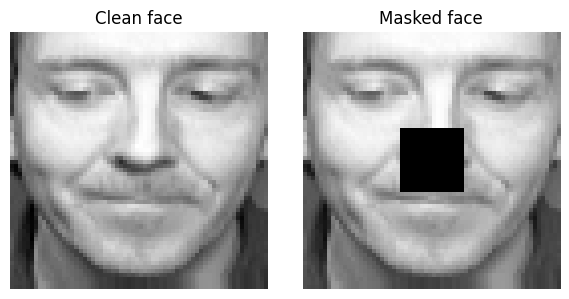

In [31]:
# Find a face where bagging and boosting respond differently to masking.
clean = predictions_by_set["clean"]
masked = predictions_by_set["masked"]

bag_changed = clean["bag_pred"] != masked["bag_pred"]
boost_changed = clean["boost_pred"] != masked["boost_pred"]

different_response = np.flatnonzero(bag_changed != boost_changed)

if len(different_response) > 0:
    idx = int(different_response[0])

    print("\nExample with different bagging/boosting response to masking")
    print("Test index:", idx)
    print("True identity:", int(y_test.iloc[idx].item()))
    print("Bagging clean prediction:", clean["bag_pred"][idx])
    print("Bagging masked prediction:", masked["bag_pred"][idx])
    print("Bagging clean and masked winning vote fraction:", clean["bag_conf"][idx], "   ",masked["bag_conf"][idx])
    print("Boosting clean prediction:", clean["boost_pred"][idx])
    print("Boosting masked prediction:", masked["boost_pred"][idx])
    print("Boosting clean/masked normalised weighted vote:", clean["boost_conf"][idx], masked["boost_conf"][idx])

    # Show class-wise bagging vote counts for the selected image.
    _, bag_clean_votes = vote_majority(X_test[idx:idx + 1], np.unique(y_train),selected_bagged_models)

    _, bag_masked_votes = vote_majority(X_masked_test[idx:idx + 1], np.unique(y_train), selected_bagged_models)
    print("Bagging votes (clean):",
          {int(c): int(np.sum(bag_clean_votes == c))
           for c in np.unique(bag_clean_votes)})
    print("Bagging votes (masked):",
          {int(c): int(np.sum(bag_masked_votes == c))
           for c in np.unique(bag_masked_votes)})

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(np.asarray(X_test)[idx].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean face")
    axes[0].axis("off")
    axes[1].imshow(np.asarray(X_masked_test)[idx].reshape(64, 64), cmap="gray")
    axes[1].set_title("Masked face")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print(
        "No test image was found where the models' prediction response differs. "
        "Inspect the full clean/masked prediction arrays and report this honestly."
    )


<h1 style = "margin-top: 50px;">Ques-3</h1>
<h3>Bias and variance as measured quantities</h3>
<h4>Keep the final clean test set fixed. Create 30 new training sets by sampling with replacement, within each identity, six
faces from that identity’s original six training faces. Refit the selected single tree, the final bagged model and the
selected boosting model on each resampled set. Do not tune again. For repetition r, let pr(xi) be the class vector, ¯p(xi)
its mean over repetitions and ei the one hot target. For boosting use the normalised weighted vote vector. Compute using given formulas</h4>

In [32]:
N_REPEATS_Q3 = 30
N_JOBS_Q3 = 4

X_train_q3 = np.asarray(X_train)
y_train_q3 = np.asarray(y_train).ravel().astype(int)
X_test_q3 = np.asarray(X_test)
y_test_q3 = np.asarray(y_test).ravel().astype(int)
Q3_CLASSES = np.arange(len(np.unique(y_train_q3)))

# Reuse the masked test set already created in Q1/Q2.
X_masked_test_q3 = np.asarray(X_test_masked).reshape(-1, 4096)

# Making 30 stratified bootstrap datasets: sample six times with replacement from each identity's original six training faces.
rng_q3 = np.random.default_rng(SEED)
resampled_train_sets_q3 = []
for r in range(N_REPEATS_Q3):
    sampled_rows = []
    for identity in Q3_CLASSES:
        identity_rows = np.flatnonzero(y_train_q3 == identity)
        sampled_rows.extend(rng_q3.choice(identity_rows, size=6, replace=True))
    sampled_rows = np.asarray(sampled_rows, dtype=int)
    resampled_train_sets_q3.append((X_train_q3[sampled_rows], y_train_q3[sampled_rows]))

print("Resampled training sets:", len(resampled_train_sets_q3))
print("Shape of each resampled X:", resampled_train_sets_q3[0][0].shape)
print("Parallel workers:", N_JOBS_Q3)

Resampled training sets: 30
Shape of each resampled X: (240, 4096)
Parallel workers: 4


<p style = "margin-top: 50px;">(a) Report measured bias squared and variance for the selected single tree, bagging and boosting models. Also report
the mean and standard deviation of test accuracy across the 30 refits.</p>

In [33]:
def q3_measure_bias_variance(class_vectors_by_repeat, y_true):
    """Compute squared bias and variance from repeated class-vote vectors."""
    mean_vectors = class_vectors_by_repeat.mean(axis=0)
    one_hot = np.eye(len(Q3_CLASSES))[np.asarray(y_true, dtype=int)]
    bias_squared = np.mean(np.sum((mean_vectors - one_hot) ** 2, axis=1))
    variance = np.mean(np.sum(
        (class_vectors_by_repeat - mean_vectors[None, :, :]) ** 2, axis=2
    ))
    repeated_predictions = np.argmax(class_vectors_by_repeat, axis=2)
    repeated_accuracy = np.mean(repeated_predictions == np.asarray(y_true)[None, :], axis=1)
    return {
        "Bias squared": float(bias_squared),
        "Variance": float(variance),
        "Mean test accuracy (%)": float(repeated_accuracy.mean() * 100),
        "Std test accuracy (percentage points)": float(repeated_accuracy.std(ddof=1) * 100),
    }


# Part - A
BAGGING_SIZE_Q3A = len(selected_bagged_models)

def q3a_one_repetition(r, X_r, y_r):
    seed = SEED + r

    # Selected Q1 single tree: keep the selected hyperparameters fixed.
    tree_r = DecisionTreeClassifier(max_depth=selected_depth, min_samples_leaf=selected_leaf, random_state=seed)
    tree_r.fit(X_r, y_r)
    tree_prob = tree_r.predict_proba(X_test_q3)
    tree_vectors = np.zeros((len(X_test_q3), len(Q3_CLASSES)))
    for j, label in enumerate(tree_r.classes_):
        tree_vectors[:, int(label)] = tree_prob[:, j]

    # Refitting a bagged model with the same number of trees as the selected Q1 model.
    rng_local = np.random.default_rng(seed)
    bagged_trees_r = []
    for _ in range(BAGGING_SIZE_Q3A):
        boot_idx = rng_local.choice(len(y_r), size=len(y_r), replace=True)
        tree_seed = SEED
        tree = DecisionTreeClassifier(max_depth=selected_depth, min_samples_leaf=selected_leaf, random_state=tree_seed)
        tree.fit(X_r[boot_idx], y_r[boot_idx])
        bagged_trees_r.append(tree)

    # Reusing vote_majority's returned individual tree predictions to form class vectors.
    _, bag_tree_predictions = vote_majority(X_test_q3, Q3_CLASSES, bagged_trees_r)
    bag_vectors = np.zeros((len(X_test_q3), len(Q3_CLASSES)))
    for i in range(len(X_test_q3)):
        bag_vectors[i] = np.bincount(np.asarray(bag_tree_predictions[:, i], dtype=int), minlength=len(Q3_CLASSES)) / len(bagged_trees_r)

    # Refiting the selected SAMME settings
    boost_r = train_samme(X_r, y_r, max_depth=MAX_DEPTH, n_rounds=N_ROUNDS, random_state=seed)
    boost_scores = samme_scores(boost_r, X_test_q3)
    total_alpha = np.sum(boost_r["alphas"])
    if total_alpha <= 0:
        raise ValueError("SAMME produced no positive total learner weight in repetition " + str(r))
    boost_vectors = np.zeros((len(X_test_q3), len(Q3_CLASSES)))
    boost_classes = boost_r["trees"][0].classes_
    for j, label in enumerate(boost_classes):
        boost_vectors[:, int(label)] = boost_scores[:, j] / total_alpha

    return r, tree_vectors, bag_vectors, boost_vectors


q3a_runs = Parallel(n_jobs=N_JOBS_Q3, backend="loky", verbose=10)(
    delayed(q3a_one_repetition)(r, X_r, y_r)
    for r, (X_r, y_r) in enumerate(resampled_train_sets_q3)
)
q3a_runs.sort(key=lambda row: row[0])

tree_vectors_q3a = np.stack([row[1] for row in q3a_runs])
bag_vectors_q3a = np.stack([row[2] for row in q3a_runs])
boost_vectors_q3a = np.stack([row[3] for row in q3a_runs])

q3a_results = pd.DataFrame({
    "Selected single tree": q3_measure_bias_variance(tree_vectors_q3a, y_test_q3),
    f"Selected bagging (B={BAGGING_SIZE_Q3A})": q3_measure_bias_variance(bag_vectors_q3a, y_test_q3),
    f"Selected SAMME (depth={MAX_DEPTH}, rounds={N_ROUNDS})": q3_measure_bias_variance(boost_vectors_q3a, y_test_q3),
}).T

print(q3a_results.round(4))

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  7.3min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed: 11.0min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed: 18.5min
[Parallel(n_jobs=4)]: Done  27 out of  30 | elapsed: 26.2min remaining:  2.9min
[Parallel(n_jobs=4)]: Done  30 out of  30 | elapsed: 29.8min finished


                                      Bias squared  Variance  \
Selected single tree                        0.3629    0.6496   
Selected bagging (B=100)                    0.5071    0.0261   
Selected SAMME (depth=4, rounds=100)        0.8885    0.0160   

                                      Mean test accuracy (%)  \
Selected single tree                                 49.3750   
Selected bagging (B=100)                             79.1667   
Selected SAMME (depth=4, rounds=100)                 28.1667   

                                      Std test accuracy (percentage points)  
Selected single tree                                                 5.5684  
Selected bagging (B=100)                                             4.6230  
Selected SAMME (depth=4, rounds=100)                                 9.6308  


<p style = "margin-top: 50px;">(b) Repeat the calculation for single trees at one shallow depth, the selected depth and one much deeper depth. At
the same three depths build 100 tree bagged ensembles. Quantify how depth changes bias and variance, and how
much variance bagging removes at each depth.</p>

In [34]:
# Part- B
"""Comparing a shallow, selected, and deeper tree; build 100-tree bagging
ensembles at each depth. This part is also parallelised on four workers."""

if selected_depth is None:
    DEPTHS_Q3B = [2, 8, None]
elif selected_depth == 2:
    DEPTHS_Q3B = [1, 2, None]
else:
    shallow_depth = 2 if selected_depth > 2 else 1
    DEPTHS_Q3B = list(dict.fromkeys([shallow_depth, selected_depth, None]))

BAGGING_SIZE_Q3B = 100
print("Depths compared:", DEPTHS_Q3B)
print("Trees per ensemble:", BAGGING_SIZE_Q3B)


def q3b_one_repetition(depth, r, X_r, y_r):
    seed = SEED + r

    single = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=selected_leaf, random_state=seed
    )
    single.fit(X_r, y_r)
    single_prob = single.predict_proba(X_test_q3)
    single_vectors = np.zeros((len(X_test_q3), len(Q3_CLASSES)))
    for j, label in enumerate(single.classes_):
        single_vectors[:, int(label)] = single_prob[:, j]

    # Inline fitting of the 100 bootstrap trees; use the existing vote_majority function.
    rng_local = np.random.default_rng(seed + (0 if depth is None else int(depth) * 1000))
    bagged_trees = []
    for _ in range(BAGGING_SIZE_Q3B):
        boot_idx = rng_local.choice(len(y_r), size=len(y_r), replace=True)
        tree_seed = int(rng_local.integers(0, 2**31 - 1))
        tree = DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=selected_leaf, random_state=tree_seed
        )
        tree.fit(X_r[boot_idx], y_r[boot_idx])
        bagged_trees.append(tree)

    _, tree_predictions = vote_majority(X_test_q3, Q3_CLASSES, bagged_trees)
    bag_vectors = np.zeros((len(X_test_q3), len(Q3_CLASSES)))
    for i in range(len(X_test_q3)):
        bag_vectors[i] = np.bincount(
            np.asarray(tree_predictions[:, i], dtype=int), minlength=len(Q3_CLASSES)
        ) / len(bagged_trees)

    # Reuse the notebook's existing pairwise_disagreement function.
    disagreement = pairwise_disagreement(tree_predictions)

    # Leaf occupancy, measured on this repetition's resampled training set.
    single_leaf_ids = single.apply(X_r)
    _, single_leaf_counts = np.unique(single_leaf_ids, return_counts=True)
    single_occupancy = {
        "leaves": len(single_leaf_counts),
        "mean_samples_per_leaf": float(single_leaf_counts.mean()),
        "singleton_leaf_fraction": float(np.mean(single_leaf_counts == 1)),
    }

    all_leaf_counts = []
    all_mean_occupancies = []
    all_singleton_fractions = []
    for tree in bagged_trees:
        _, leaf_counts = np.unique(tree.apply(X_r), return_counts=True)
        all_leaf_counts.append(len(leaf_counts))
        all_mean_occupancies.append(float(leaf_counts.mean()))
        all_singleton_fractions.append(float(np.mean(leaf_counts == 1)))

    bagged_occupancy = {
        "leaves": float(np.mean(all_leaf_counts)),
        "mean_samples_per_leaf": float(np.mean(all_mean_occupancies)),
        "singleton_leaf_fraction": float(np.mean(all_singleton_fractions)),
    }

    single_accuracy = float(np.mean(np.argmax(single_vectors, axis=1) == y_test_q3))
    bag_accuracy = float(np.mean(np.argmax(bag_vectors, axis=1) == y_test_q3))

    return {
        "depth": depth, "repetition": r,
        "single_vectors": single_vectors, "bag_vectors": bag_vectors,
        "single_accuracy": single_accuracy, "bag_accuracy": bag_accuracy,
        "single_occupancy": single_occupancy, "bag_occupancy": bagged_occupancy,
        "disagreement": disagreement,
    }

q3b_jobs = [
    (depth, r, X_r, y_r)
    for depth in DEPTHS_Q3B
    for r, (X_r, y_r) in enumerate(resampled_train_sets_q3)
]
q3b_runs = Parallel(n_jobs=N_JOBS_Q3, backend="loky", verbose=10)(
    delayed(q3b_one_repetition)(depth, r, X_r, y_r)
    for depth, r, X_r, y_r in q3b_jobs
)
print("Completed Q3(b) jobs:", len(q3b_runs))

q3b_depth_metrics = {}
q3b_rows = []
q3b_variance_rows = []
for depth in DEPTHS_Q3B:
    group = sorted([row for row in q3b_runs if row["depth"] == depth], key=lambda row: row["repetition"])
    single_vectors_all = np.stack([row["single_vectors"] for row in group])
    bag_vectors_all = np.stack([row["bag_vectors"] for row in group])
    single_metrics = q3_measure_bias_variance(single_vectors_all, y_test_q3)
    bag_metrics = q3_measure_bias_variance(bag_vectors_all, y_test_q3)

    single_acc_mean = np.mean([row["single_accuracy"] for row in group]) * 100
    single_acc_sd = np.std([row["single_accuracy"] for row in group], ddof=1) * 100
    bag_acc_mean = np.mean([row["bag_accuracy"] for row in group]) * 100
    bag_acc_sd = np.std([row["bag_accuracy"] for row in group], ddof=1) * 100
    single_leaves = np.mean([row["single_occupancy"]["leaves"] for row in group])
    single_occ = np.mean([row["single_occupancy"]["mean_samples_per_leaf"] for row in group])
    single_singletons = np.mean([row["single_occupancy"]["singleton_leaf_fraction"] for row in group])
    bag_leaves = np.mean([row["bag_occupancy"]["leaves"] for row in group])
    bag_occ = np.mean([row["bag_occupancy"]["mean_samples_per_leaf"] for row in group])
    bag_singletons = np.mean([row["bag_occupancy"]["singleton_leaf_fraction"] for row in group])
    disagreement = np.mean([row["disagreement"] for row in group])

    q3b_depth_metrics[depth] = {
        "single_metrics": single_metrics, "bag_metrics": bag_metrics,
        "single_accuracy_mean": single_acc_mean, "bag_accuracy_mean": bag_acc_mean,
        "disagreement": disagreement,
    }
    q3b_rows.extend([
        {"Depth": str(depth), "Model": "Single tree",
         "Bias squared": single_metrics["Bias squared"], "Variance": single_metrics["Variance"],
         "Mean accuracy (%)": single_acc_mean, "Accuracy SD (pp)": single_acc_sd,
         "Mean leaves": single_leaves, "Mean samples/leaf": single_occ,
         "Singleton leaf fraction": single_singletons, "Pairwise disagreement": np.nan},
        {"Depth": str(depth), "Model": "Bagging (B=100)",
         "Bias squared": bag_metrics["Bias squared"], "Variance": bag_metrics["Variance"],
         "Mean accuracy (%)": bag_acc_mean, "Accuracy SD (pp)": bag_acc_sd,
         "Mean leaves": bag_leaves, "Mean samples/leaf": bag_occ,
         "Singleton leaf fraction": bag_singletons, "Pairwise disagreement": disagreement},
    ])
    single_var = single_metrics["Variance"]
    bag_var = bag_metrics["Variance"]
    q3b_variance_rows.append({
        "Depth": str(depth), "Single-tree variance": single_var, "Bagged variance": bag_var,
        "Variance reduction (%)": (100 * (single_var - bag_var) / single_var if single_var > 0 else np.nan),
        "Single-tree accuracy (%)": single_acc_mean, "Bagged accuracy (%)": bag_acc_mean,
        "Accuracy improvement (pp)": bag_acc_mean - single_acc_mean,
    })

q3b_table = pd.DataFrame(q3b_rows)
q3b_variance_comparison = pd.DataFrame(q3b_variance_rows)
print(q3b_table.round(4))
print(q3b_variance_comparison.round(4))


Depths compared: [2, 8, None]
Trees per ensemble: 100


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   45.9s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  1.9min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  2.3min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  4.4min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  7.0min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed: 10.9min
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed: 16.1min
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed: 26.9min
[Parallel(n_jobs=4)]: Done  90 out of  90 | elapsed: 36.0min finished


Completed Q3(b) jobs: 90
  Depth            Model  Bias squared  Variance  Mean accuracy (%)  \
0     2      Single tree        0.9200    0.0370             5.5833   
1     2  Bagging (B=100)        0.9329    0.0112            12.5417   
2     8      Single tree        0.7994    0.1269            14.2917   
3     8  Bagging (B=100)        0.8122    0.0170            44.1667   
4  None      Single tree        0.3629    0.6496            49.3750   
5  None  Bagging (B=100)        0.5085    0.0258            77.2083   

   Accuracy SD (pp)  Mean leaves  Mean samples/leaf  Singleton leaf fraction  \
0            1.4582       3.0000            80.0000                   0.0000   
1            5.8398       3.1637            76.7267                   0.0001   
2            2.5147       9.4000            25.6323                   0.0000   
3            5.4371      10.7107            22.7083                   0.0009   
4            5.5684      40.0000             6.0000                   0.0000 

<p style = "margin-top: 50px;">(c) Determine whether the deepest tree is necessarily the depth at which bagging gives the largest improvement
in test accuracy. Your answer must use your measured bias, variance, leaf occupancy and disagreement results
rather than a generic statement about the bias variance tradeoff.</p>

In [35]:
# Part - C
best_improvement_row = q3b_variance_comparison.loc[q3b_variance_comparison["Accuracy improvement (pp)"].idxmax()]
deepest_label = str(DEPTHS_Q3B[-1])
deepest_row = q3b_variance_comparison[q3b_variance_comparison["Depth"] == deepest_label].iloc[0]

print("Depth with the largest measured bagging accuracy improvement:", best_improvement_row["Depth"])
print("Largest accuracy improvement (percentage points):", round(best_improvement_row["Accuracy improvement (pp)"], 4))
print("Deepest tested depth:", deepest_label)
print("Deepest-depth accuracy improvement (percentage points):", round(deepest_row["Accuracy improvement (pp)"], 4))
print("Does the deepest tested tree give the largest improvement?", bool(best_improvement_row["Depth"] == deepest_label))
print("\nUsing q3b_table to compare leaf occupancy and pairwise disagreement and "
      "q3b_variance_comparison to compare variance reduction and accuracy improvement.")

print(q3b_variance_comparison.round(4))



Depth with the largest measured bagging accuracy improvement: 8
Largest accuracy improvement (percentage points): 29.875
Deepest tested depth: None
Deepest-depth accuracy improvement (percentage points): 27.8333
Does the deepest tested tree give the largest improvement? False

Using q3b_table to compare leaf occupancy and pairwise disagreement and q3b_variance_comparison to compare variance reduction and accuracy improvement.
  Depth  Single-tree variance  Bagged variance  Variance reduction (%)  \
0     2                0.0370           0.0112                 69.6050   
1     8                0.1269           0.0170                 86.6329   
2  None                0.6496           0.0258                 96.0255   

   Single-tree accuracy (%)  Bagged accuracy (%)  Accuracy improvement (pp)  
0                    5.5833              12.5417                     6.9583  
1                   14.2917              44.1667                    29.8750  
2                   49.3750            

<p style = "margin-top: 50px;">(d) End with one table for the selected single tree, bagging and boosting models containing clean test accuracy,
masked test accuracy, bias squared and variance. Using this table together with your earlier plots, explain which
model is most stable, which is most sensitive to the missing region, and whether the model with the lowest
variance is necessarily the model with the best test accuracy</p>

In [36]:
# Part - D
clean_q2 = predictions_by_set["clean"]
masked_q2 = predictions_by_set["masked"]

q3d_bias_variance = {
    "Single decision tree": q3_measure_bias_variance(tree_vectors_q3a, y_test_q3),
    "Bagging": q3_measure_bias_variance(bag_vectors_q3a, y_test_q3),
    "SAMME boosting": q3_measure_bias_variance(boost_vectors_q3a, y_test_q3),
}
q3d_prediction_keys = {
    "Single decision tree": "tree_pred",
    "Bagging": "bag_pred",
    "SAMME boosting": "boost_pred",
}

q3d_rows = []
for model_name, pred_key in q3d_prediction_keys.items():
    clean_acc = float(np.mean(np.asarray(clean_q2[pred_key]).ravel() == y_test_q3))
    masked_acc = float(np.mean(np.asarray(masked_q2[pred_key]).ravel() == y_test_q3))
    metrics = q3d_bias_variance[model_name]
    q3d_rows.append({
        "Model": model_name,
        "Clean test accuracy (%)": 100 * clean_acc,
        "Masked test accuracy (%)": 100 * masked_acc,
        "Accuracy drop (pp)": 100 * (clean_acc - masked_acc),
        "Bias squared": metrics["Bias squared"],
        "Variance": metrics["Variance"],
    })

q3d_final_table = pd.DataFrame(q3d_rows)
print(q3d_final_table.round(4))

most_stable_q3 = q3d_final_table.loc[q3d_final_table["Variance"].idxmin(), "Model"]
most_mask_sensitive_q3 = q3d_final_table.loc[q3d_final_table["Accuracy drop (pp)"].idxmax(), "Model"]
best_clean_q3 = q3d_final_table.loc[q3d_final_table["Clean test accuracy (%)"].idxmax(), "Model"]
print("Lowest measured variance (most stable across resamples):", most_stable_q3)
print("Largest clean-to-masked accuracy drop (most mask-sensitive):", most_mask_sensitive_q3)
print("Highest clean test accuracy:", best_clean_q3)
print("The lowest-variance model is not necessarily the highest-accuracy model; compare both columns above.")

                  Model  Clean test accuracy (%)  Masked test accuracy (%)  \
0  Single decision tree                    56.25                       7.5   
1               Bagging                    86.25                      67.5   
2        SAMME boosting                    50.00                      45.0   

   Accuracy drop (pp)  Bias squared  Variance  
0               48.75        0.3629    0.6496  
1               18.75        0.5071    0.0261  
2                5.00        0.8885    0.0160  
Lowest measured variance (most stable across resamples): SAMME boosting
Largest clean-to-masked accuracy drop (most mask-sensitive): Single decision tree
Highest clean test accuracy: Bagging
The lowest-variance model is not necessarily the highest-accuracy model; compare both columns above.
